In [235]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import pathlib
import sys

In [236]:
def dispatch_plot(df_dispatch):
    # Copy dataframe
    df_dispatch = df_dispatch.copy()
    
    fig = plt.figure(figsize=(9, 5))
    time = df_dispatch.index.hour
    plt.plot(
        time,
        df_dispatch["load"],
        color="black",
        linewidth=3,
        label="load",
    )
    plt.plot(
        time,
        df_dispatch["load"] + df_dispatch["storage charge"],
        color="black",
        linewidth=2,
        linestyle="--",
        label="load + storage charge",
    )
    plt.stackplot(
        time,
        df_dispatch["solar"], df_dispatch["wind"], df_dispatch["hydro"], df_dispatch["thermal"],
        df_dispatch["storage discharge"], df_dispatch["unserved energy"],
        labels=("solar", "wind", "hydro", "thermal", "storage discharge", "unserved energy"),
        colors=("gold", "skyblue", "steelblue", "lightgrey", "purple", "red"),
    )
    plt.legend(fontsize=9)
    plt.axis([0, 23, 0, None])
    plt.xlabel("Time (h)")
    plt.ylabel("MW")

    return fig

def load_shed_plot(df_load_shed):

    loads = [col.strip("_baseline") for col in df_load_shed.columns]
    
    fig = plt.figure(figsize=(5, 9))
    plt.imshow(df_load_shed.T, cmap="Reds", vmin=0, vmax=1)
    plt.yticks(np.arange(len(loads)), loads)
    plt.xticks(np.arange(0, 24, 5))
    plt.ylabel("Load Bus")
    plt.xlabel("Time (h)")
    
    return fig

In [242]:
system_config = "RTS-ORB"

In [243]:
curr_dir = pathlib.Path(".")
results_dir = curr_dir / "results" / system_config
dispatch_dir = results_dir / "dispatch-results"
plots_dir = results_dir / "dispatch-plots"
plots_dir.mkdir(parents=True, exist_ok=True)

In [244]:
df_results = pd.read_csv(results_dir / "ols_results_5yrs.csv")
df_results

,scenario_seed,date,cost,unserved_energy,opt_status,lp_unserved_energy,lp_cost,event_type
0,1,2020-08-13,2.992684e+03,0.299268,2,0.299268,2.992684e+03,capacity-limited
1,2,2020-07-29,7.965751e+06,796.575149,2,796.575149,7.965751e+06,storage-limited
2,3,2020-07-26,1.196625e+07,1196.625198,2,1196.625198,1.196625e+07,storage-limited
3,4,2020-07-29,8.739358e+04,8.739358,2,8.739358,8.739358e+04,capacity-limited
4,4,2020-08-10,1.773252e+06,177.325180,2,177.325182,1.773252e+06,capacity-limited


capacity-limited 1 2020-08-13


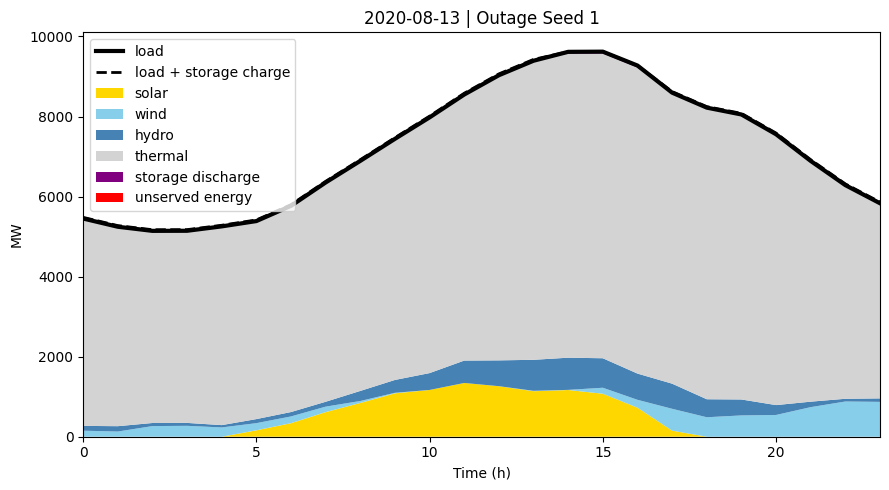

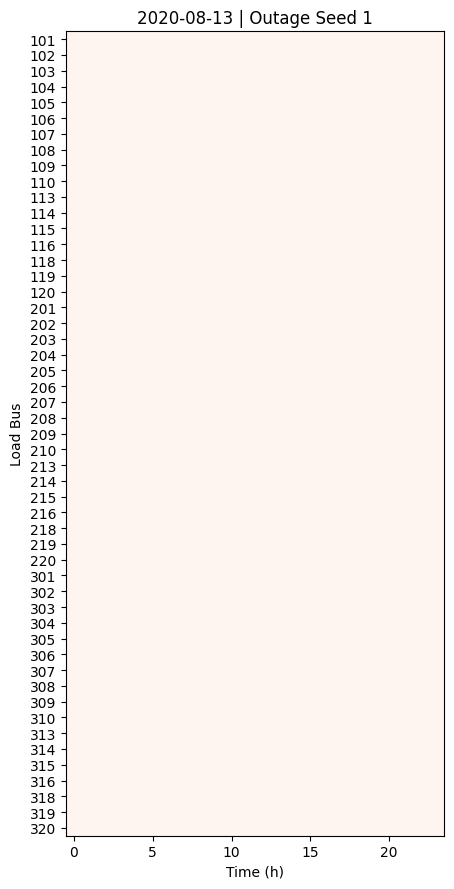

storage-limited 2 2020-07-29


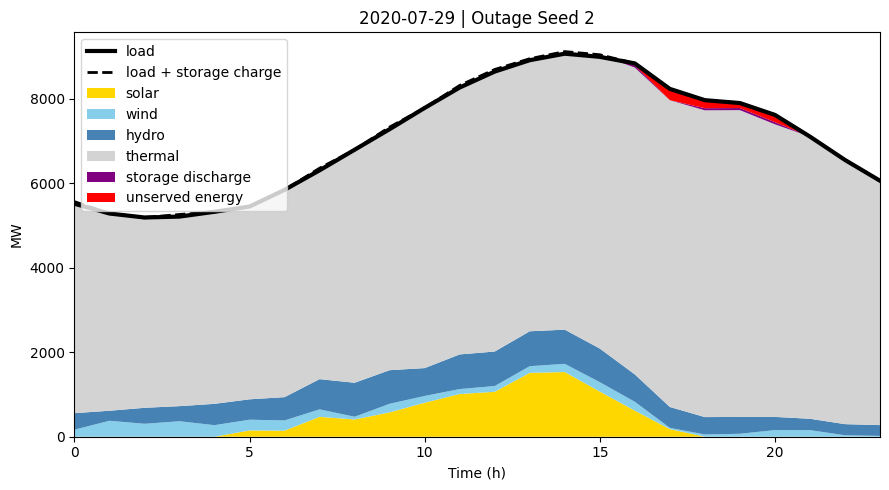

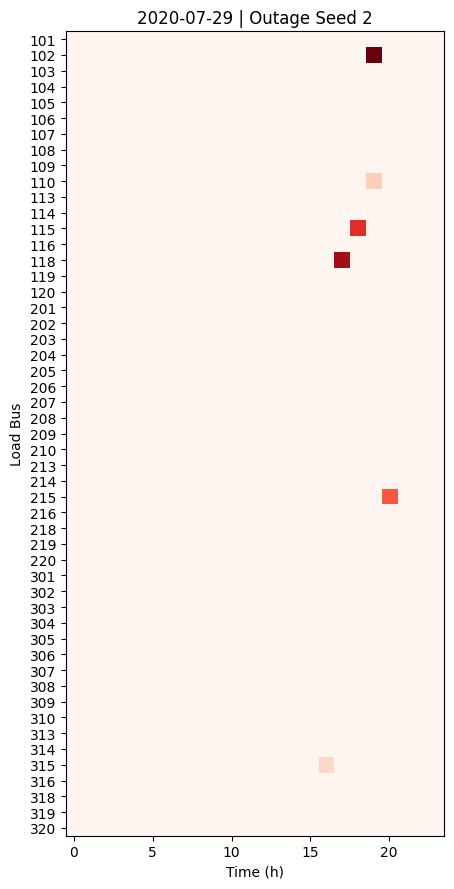

storage-limited 3 2020-07-26


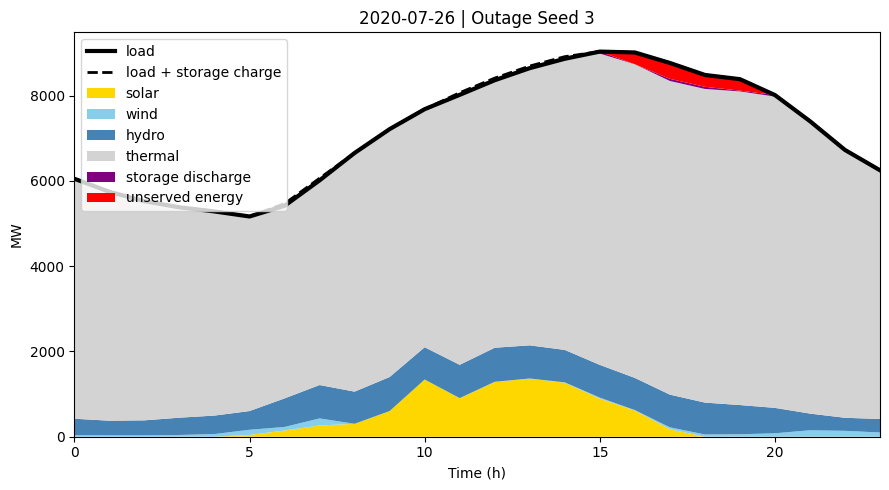

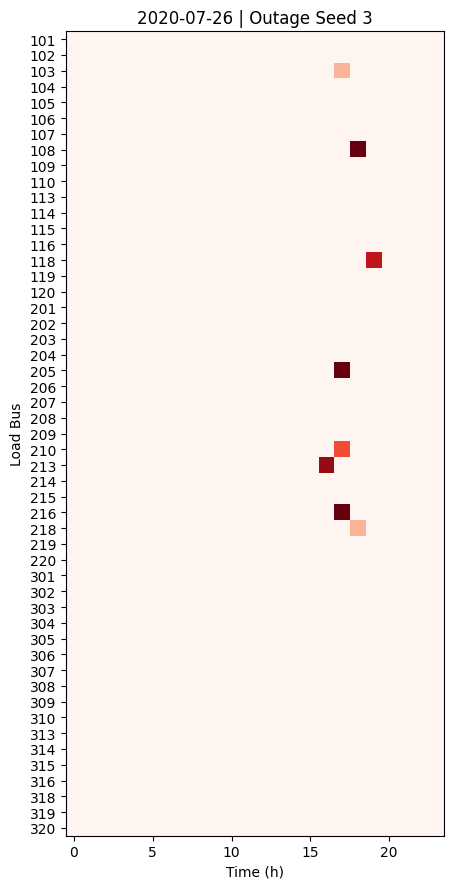

capacity-limited 4 2020-07-29


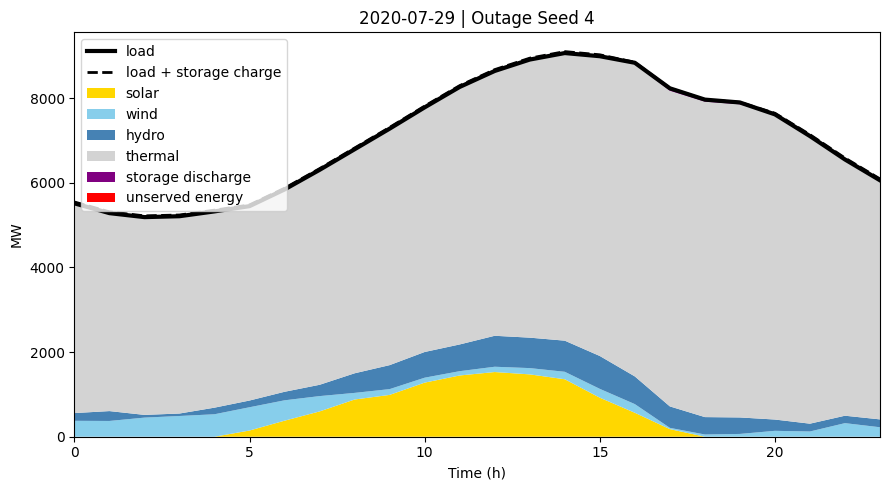

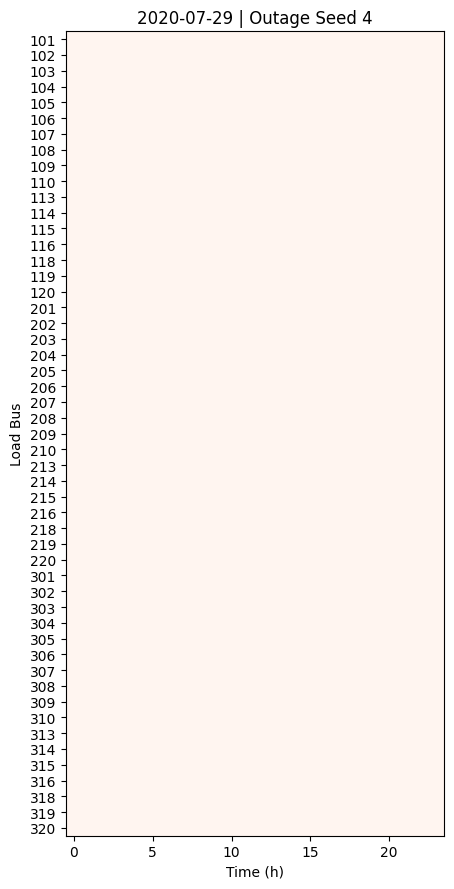

capacity-limited 4 2020-08-10


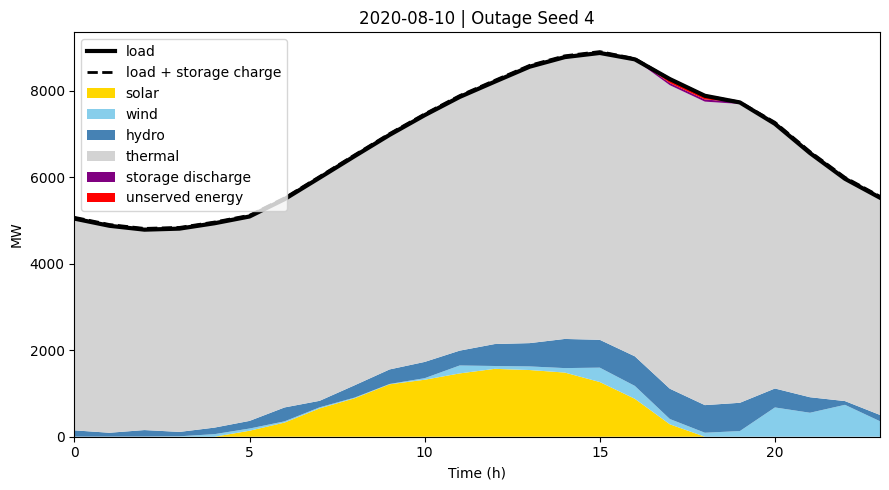

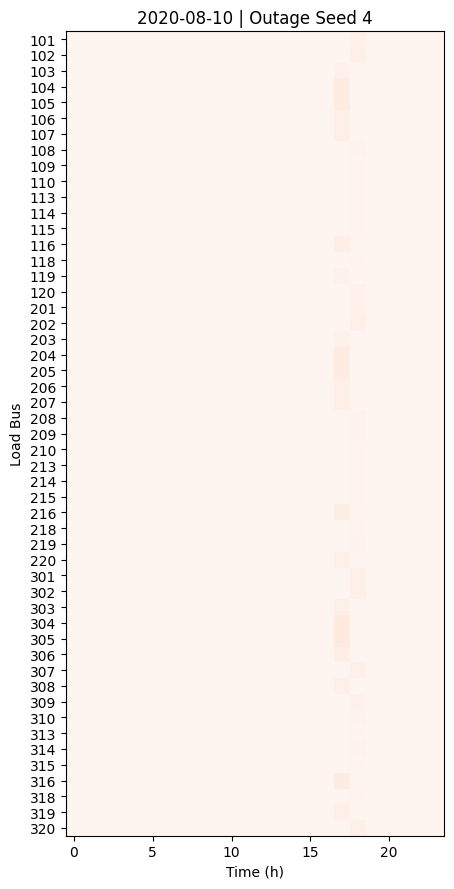

In [245]:
for i, row in df_results.iterrows():
    print(row.event_type, row.scenario_seed, row.date)

    # Create dispatch plot
    df_dispatch = pd.read_csv(dispatch_dir / f"dispatch_results_seed{row.scenario_seed}_{row.date}.csv", index_col=[0])
    df_dispatch.index = pd.to_datetime(df_dispatch.index)
    fig = dispatch_plot(df_dispatch)
    plt.title(f"{row.date} | Outage Seed {row.scenario_seed}")
    plt.savefig(plots_dir / f"dispatch_plot_seed{row.scenario_seed}_{row.date}.pdf", dpi=300)
    plt.tight_layout()
    plt.legend(loc="upper left")
    plt.show()
    plt.close()

    # Create load shed plot
    df_load_shed = pd.read_csv(dispatch_dir / f"load_shed_results_seed{row.scenario_seed}_{row.date}.csv", index_col=[0])
    df_load_shed.index = pd.to_datetime(df_load_shed.index)
    fig = load_shed_plot(df_load_shed)
    plt.title(f"{row.date} | Outage Seed {row.scenario_seed}")
    plt.savefig(plots_dir / f"load_shed_plot_seed{row.scenario_seed}_{row.date}.pdf", dpi=300)
    plt.tight_layout()
    plt.show()
    plt.close()
    
    # Analyze fairness

In [241]:
# Visualize portfolios
system_configs = ["RTS-GMLC", "RTS-ORB", "RTS-ORB-HR"]
index = [
    "Peak",
    "Coal",
    "Hydro",
    "NG",
    "Nuclear",
    "Oil",
    "Solar",
    "Storage",
    "Sync_Cond",
    "Wind",
]
df_sys = pd.DataFrame(index=index, columns=system_configs)
df_sys.loc["Peak",:] = [8191.8, 9830.2, 9830.2]

config_dir = curr_dir / "system-config"
for config in system_configs:
    df_gen = pd.read_csv(config_dir / config / "gen.csv", index_col=[0])
    df_cap = df_gen.groupby(["Fuel"]).sum()["PMax MW"]
    df_cap.index.name = None
    df_sys.loc[df_cap.index, config] = df_cap.values

df_sys = df_sys.rename(index={"NG": "Natural Gas"})
df_sys = df_sys.rename(columns={"RTS-ORB": "RTS-OLS", "RTS-ORB-HR": "RTS-OLS-HR"})
df_sys = df_sys.apply(pd.to_numeric, errors="coerce").fillna(0)

In [210]:
df_sys

,RTS-GMLC,RTS-OLS,RTS-OLS-HR
Peak,8191.8,9830.2,9830.2
Coal,2317.0,2317.0,1320.0
Hydro,1000.0,1000.0,1000.0
Natural Gas,5035.0,5035.0,5035.0
Nuclear,400.0,400.0,400.0
Oil,324.0,324.0,324.0
Solar,2915.9,2915.9,4415.9
Storage,50.0,50.0,1050.0
Sync_Cond,0.0,0.0,0.0
Wind,2507.9,2507.9,3007.9


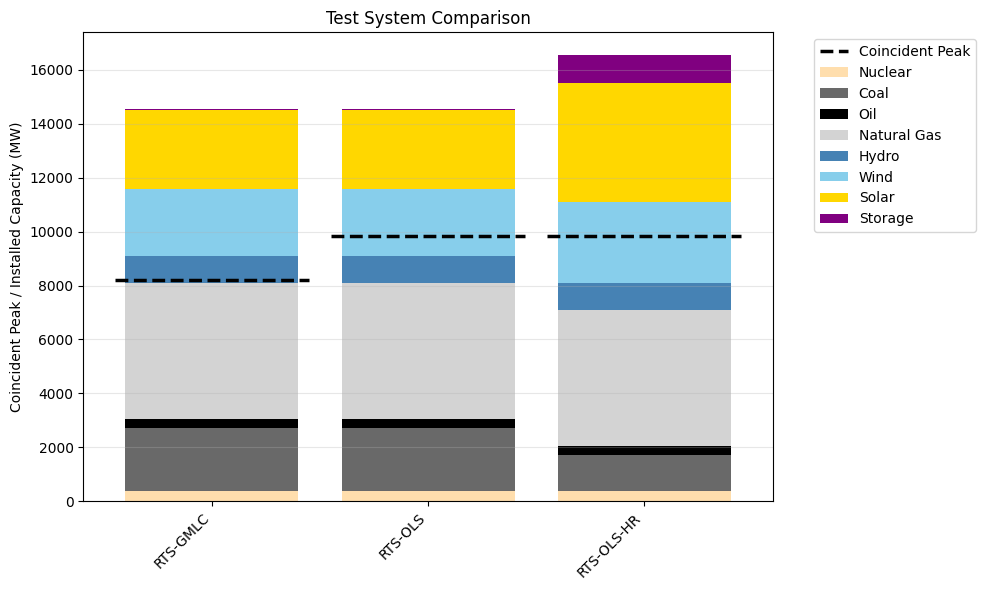

In [220]:
gen_cols = ["Nuclear", "Coal", "Oil", "Natural Gas", "Hydro", "Wind", "Solar", "Storage"]

color_dict = {
    "Nuclear": "navajowhite",
    "Coal": "dimgrey",
    "Oil": "black",
    "Natural Gas": "lightgrey",
    "Hydro": "steelblue",
    "Wind": "skyblue",
    "Solar": "gold",
    "Storage": "purple"
}

fig = plt.figure(figsize=(10,6))
bottom = np.zeros(len(df_sys.columns))
for gen in gen_cols:
    plt.bar(
        df_sys.columns,
        df_sys.loc[gen],
        bottom=bottom,
        label=gen,
        color=color_dict[gen],
    )
    bottom += df_sys.loc[gen].values

xticks = np.arange(len(df_sys.columns))
for i, config in enumerate(df_sys.columns):
    label = "Coincident Peak" if i == 0 else None
    plt.plot([xticks[i]-0.45, xticks[i]+0.45], [df_sys.loc["Peak", config], df_sys.loc["Peak", config]], linewidth=2.5, linestyle="--", color="black", label=label)

plt.ylabel("Coincident Peak / Installed Capacity (MW)")
plt.title("Test System Comparison")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(axis="y", alpha=0.3)
plt.xticks(xticks, rotation=45, ha="right")
plt.tight_layout()
plt.savefig(curr_dir / "figures" / "system_comparison.pdf", dpi=350)
plt.show()

array([0. , 0.2, 0.4, 0.6, 0.8, 1. ])

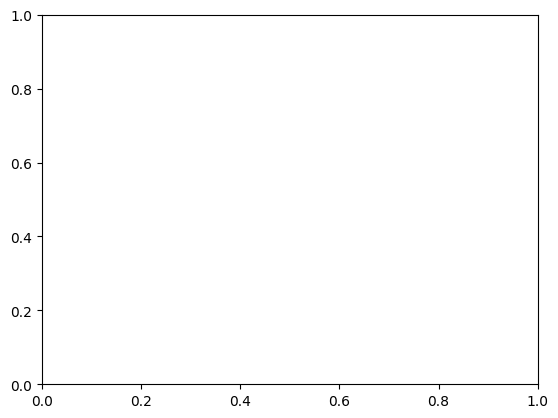